# Attention: Give the Waiter a Notepad 📝

In Notebook 1, the waiter kept everything in their head and fell apart on long orders. The fix sounds almost too simple:

> **While listening,** jot down a note after every word.
> **While writing the ticket,** glance back at the notes and look at just the part you need right now.

This is **attention** (Bahdanau et al., 2015), and it is the idea that later grew into Transformers.

```
 WITHOUT ATTENTION                        WITH ATTENTION
 words → [ one memory ] → ticket          words → note note note note note
                                                    ▲    ▲    ▲    ▲    ▲
                                                    └── the decoder looks ──▶ ticket
                                                        again at EVERY word
```

**Today's experiments**

| # | Experiment | The question |
|---|---|---|
| 1 | Attention by hand | What is attention actually doing, in plain arithmetic? |
| 2 | The showdown | Notepad vs. no notes vs. a much bigger brain |
| 3 | Read the waiter's eyes | Where does the model look for each word? |
| 4 | Watch them learn to read | How does that focus develop during training? |
| 5 | Smudge the notepad | Is attention really used, or just a pretty picture? |
| 6 | Try to break it | Where does this waiter still fail? |

## Setup and data (the same as Notebook 1)

The same seed gives the same training orders. The whole notebook takes about 2 minutes on a GPU. This time we also test on 11, 12 and 13-item orders, which are **larger than anything in training**.

In [1]:
import random, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("Training on:", torch.cuda.get_device_name(0) if device == "cuda" else device)

SEED = 42
PLAIN_COLOR, ATTENTION_COLOR, BIG_COLOR = "#eb6834", "#2a78d6", "#1baf7a"   # each model keeps its color
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10})

Training on: NVIDIA RTX PRO 6000 Blackwell Workstation Edition


In [2]:
MENU = {"drink":   ["coke", "water", "coffee", "tea", "juice", "lemonade", "milkshake", "soda"],
        "main":    ["burger", "pizza", "pasta", "salad", "steak", "taco", "sandwich", "soup"],
        "dessert": ["cake", "pie", "brownie", "cookie", "donut", "pudding", "waffle", "muffin"]}
STATION_OF = {dish: station for station, dishes in MENU.items() for dish in dishes}
NUMBER_WORDS = ["one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
OPENERS = ["hi can i get", "i would like", "we will have", "give me"]
CLOSERS = ["please", "thanks", ""]
plural = lambda dish: dish + ("es" if dish.endswith("ch") else "s")

def make_order(n_items):
    """Returns one (what the customer says, what the ticket must say) pair of word lists."""
    dishes = random.sample(list(STATION_OF), n_items)
    quantities = [random.randint(1, 9) for _ in dishes]

    said = random.choice(OPENERS).split()
    for i, (qty, dish) in enumerate(zip(quantities, dishes)):
        said.append("a" if qty == 1 and random.random() < 0.5 else NUMBER_WORDS[qty - 1])
        said.append(dish if qty == 1 else plural(dish))
        if i < n_items - 2:     said.append(random.choice([",", "and", "plus"]))
        elif i == n_items - 2:  said.append("and")
    said += random.choice(CLOSERS).split()

    # The kitchen's rule: drinks first, then mains, then desserts
    ticket = []
    for station in MENU:
        for qty, dish in zip(quantities, dishes):
            if STATION_OF[dish] == station:
                ticket += [str(qty), dish]
    return said, ticket

In [3]:
TEST_SIZES = range(1, 14)

random.seed(SEED)
train_orders = [make_order(random.randint(1, 10)) for _ in range(120_000)]
random.seed(SEED + 1)
test_bank = {n: [make_order(n) for _ in range(500)] for n in TEST_SIZES}   # never used for training

PAD, SOS, EOS = 0, 1, 2
SPECIALS = ["<pad>", "<sos>", "<eos>"]
src_words = SPECIALS + sorted({w for said, _ in train_orders for w in said})
tgt_words = SPECIALS + sorted({w for _, ticket in train_orders for w in ticket})
src_id = {w: i for i, w in enumerate(src_words)}
tgt_id = {w: i for i, w in enumerate(tgt_words)}

def make_batch(orders):
    """Turns orders into padded GPU tensors of word ids."""
    src = [torch.tensor([src_id[w] for w in said]) for said, _ in orders]
    tgt = [torch.tensor([SOS] + [tgt_id[w] for w in ticket] + [EOS]) for _, ticket in orders]
    src_len = torch.tensor([len(s) for s in src])
    return (pad_sequence(src, batch_first=True, padding_value=PAD).to(device), src_len.to(device),
            pad_sequence(tgt, batch_first=True, padding_value=PAD).to(device))

# The whole training set lives on the GPU, so grabbing a batch is instant
X_train, L_train, Y_train = make_batch(train_orders)

print(f"{len(train_orders):,} training orders, 1 to 10 items each. Test sizes: 1 to {max(TEST_SIZES)} items.")

120,000 training orders, 1 to 10 items each. Test sizes: 1 to 13 items.


## Experiment 1: attention by hand

Before any neural network, let's do attention with numbers you can check yourself. Suppose the notepad has three notes, and each note is a tiny vector: `[how drink-like, how food-like]`. The waiter's current thought is "*I need a drink next*".

Attention always has the same **three steps**:

1. **Score:** how well does each note match what I need right now?
2. **Softmax:** turn the scores into weights that add up to 1.
3. **Blend:** add up the notes, each multiplied by its weight. This blend is the **context vector**.

In [4]:
notes = torch.tensor([[0.1, 2.0],    # note written at "burgers"
                      [2.0, 0.1],    # note written at "cokes"
                      [0.1, 0.1]])   # note written at "please"
need_a_drink = torch.tensor([2.0, 0.0])

scores  = notes @ need_a_drink           # Step 1: score each note (a dot product here)
weights = F.softmax(scores, dim=0)       # Step 2: turn scores into weights
context = weights @ notes                # Step 3: blend the notes

for word, s, w in zip(["burgers", "cokes", "please"], scores.tolist(), weights.tolist()):
    print(f"{word:<8} score = {s:.1f}   weight = {w:.2f}   {'█' * round(w * 30)}")
print(f"\nContext vector = {[round(v, 2) for v in context.tolist()]}: almost exactly the 'cokes' note.")

burgers  score = 0.2   weight = 0.02   █
cokes    score = 4.0   weight = 0.96   █████████████████████████████
please   score = 0.2   weight = 0.02   █

Context vector = [1.92, 0.14]: almost exactly the 'cokes' note.


Nearly all the weight went to `cokes`. And since every step is differentiable, the model can **learn** what to look for using ordinary backpropagation.

### The same three steps in the real model

Real notes are learned vectors instead of hand-made ones: they're simply the **encoder's hidden state after each word**, which Notebook 1 threw away! Step 1 uses a small learned network (Bahdanau's additive score) rather than a dot product:

$$\text{score}_i = v^\top \tanh(W_{q}\, s + W_{n}\, h_i) \qquad \alpha = \text{softmax}(\text{score}) \qquad c = \sum_i \alpha_i h_i$$

Here $s$ is the decoder's current state (*what I need*), and $h_i$ is the note at word $i$.

In [5]:
class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.W_query = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_note  = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.v       = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, need, notes, readable):
        # Step 1: score each note against what the decoder needs
        scores = self.v(torch.tanh(self.W_query(need).unsqueeze(1) + self.W_note(notes))).squeeze(2)
        scores = scores.masked_fill(~readable, -1e9)     # never look at padding
        # Step 2: scores become weights that add up to 1
        weights = F.softmax(scores, dim=1)
        # Step 3: blend the notes
        context = (weights.unsqueeze(1) @ notes).squeeze(1)
        return context, weights

### Exactly one thing changes

To be a fair test, the encoder is **unchanged**. It just hands over its notes as well as its memory. Here's what changes in the decoder:

```diff
  class Decoder:
-     step(last_word, memory)
+     step(last_word, memory, notes)
+         context, weights = attention(memory, notes)       # glance at the notepad
-         gru_input = embed(last_word)
+         gru_input = embed(last_word) + context            # write with the note in view
-         scores = to_vocab(gru_output)
+         scores = to_vocab(gru_output + context)           # ("+" here means concatenate)
```

In [6]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.gru = nn.GRU(emb_dim, hidden_dim, batch_first=True)

    def forward(self, src, src_len):
        packed = pack_padded_sequence(self.embedding(src), src_len.cpu(),
                                      batch_first=True, enforce_sorted=False)
        packed_notes, memory = self.gru(packed)
        notes, _ = pad_packed_sequence(packed_notes, batch_first=True, total_length=src.size(1))
        return notes, memory       # NEW: one note per word, plus the final memory

class PlainDecoder(nn.Module):
    """The waiter from Notebook 1: receives the notes, but ignores them."""
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.gru = nn.GRU(emb_dim, hidden_dim, batch_first=True)
        self.to_vocab = nn.Linear(hidden_dim, vocab_size)

    def forward(self, last_word, memory, notes, readable):
        output, memory = self.gru(self.embedding(last_word).unsqueeze(1), memory)
        return self.to_vocab(output.squeeze(1)), memory, None

class AttentionDecoder(nn.Module):
    """The waiter with a notepad."""
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.attention = Attention(hidden_dim)
        self.gru = nn.GRU(emb_dim + hidden_dim, hidden_dim, batch_first=True)
        self.to_vocab = nn.Linear(hidden_dim + hidden_dim, vocab_size)

    def forward(self, last_word, memory, notes, readable):
        context, weights = self.attention(memory[-1], notes, readable)
        gru_input = torch.cat([self.embedding(last_word), context], dim=1).unsqueeze(1)
        output, memory = self.gru(gru_input, memory)
        return self.to_vocab(torch.cat([output.squeeze(1), context], dim=1)), memory, weights

MAX_TICKET = 27

class Seq2Seq(nn.Module):
    def __init__(self, decoder_class, emb_dim=64, hidden_dim=128):
        super().__init__()
        self.encoder = Encoder(len(src_words), emb_dim, hidden_dim)
        self.decoder = decoder_class(len(tgt_words), emb_dim, hidden_dim)

    def forward(self, src, src_len, tgt):                 # training: teacher forcing
        notes, memory = self.encoder(src, src_len)
        readable = src != PAD
        all_scores, all_weights = [], []
        for t in range(tgt.size(1) - 1):
            scores, memory, weights = self.decoder(tgt[:, t], memory, notes, readable)
            all_scores.append(scores); all_weights.append(weights)
        return torch.stack(all_scores, dim=1), all_weights

    @torch.no_grad()
    def generate(self, src, src_len, smudged=None):       # real use: feeds itself
        notes, memory = self.encoder(src, src_len)
        readable = src != PAD
        if smudged is not None:                           # used in Experiment 5
            readable = readable & ~smudged
        word = torch.full((src.size(0),), SOS, device=src.device)
        written, looked_at = [], []
        for _ in range(MAX_TICKET):
            scores, memory, weights = self.decoder(word, memory, notes, readable)
            word = scores.argmax(dim=1)
            written.append(word); looked_at.append(weights)
        return torch.stack(written, dim=1), looked_at

## Experiment 2: the showdown 🥊

Three waiters, with the same data, the same training budget and the same test orders:

| Waiter | Memory size | Notepad? | The question it answers |
|---|---|---|---|
| **No notes** | 128 | No | The baseline from Notebook 1 |
| **Bigger brain** | 512 (4× larger) | No | Could we fix this by just making the memory bigger? |
| **Notepad** | 128 | Yes | Does attention beat raw memory? |

While the notepad waiter trains, we'll also save snapshots of their attention, for Experiment 4.

In [7]:
def train_model(model, steps=2000, batch_size=512, max_lr=2e-3, on_step=None):
    optimizer = torch.optim.Adam(model.parameters(), lr=max_lr)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr, total_steps=steps)
    losses, start = [], time.time()
    for step in range(steps):
        if on_step: on_step(step, model)
        idx = torch.randint(0, len(X_train), (batch_size,), device=device)
        src_len = L_train[idx]
        src = X_train[idx, :src_len.max()]                       # trim unneeded padding
        tgt = Y_train[idx, :(Y_train[idx] != PAD).sum(1).max()]

        logits = model(src, src_len, tgt)[0]
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),   # predict each NEXT word
                               tgt[:, 1:].reshape(-1), ignore_index=PAD)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)        # RNN safety belt
        optimizer.step()
        schedule.step()
        losses.append(loss.item())
        if step % 500 == 0 or step == steps - 1:
            print(f"step {step:>4} | loss {loss.item():.3f} | {time.time() - start:5.1f}s")
    model.train_seconds = time.time() - start
    return losses

def ids_to_words(ids):
    words = []
    for i in ids:
        if i == EOS: break
        if i > EOS: words.append(tgt_words[i])
    return words

def read_tickets(model, orders):
    src, src_len, _ = make_batch(orders)
    return [ids_to_words(row) for row in model.generate(src, src_len)[0].tolist()]

def split_items(ticket):
    return [(ticket[i], ticket[i + 1]) for i in range(0, len(ticket) - 1, 2)]

def score(model, bank):
    """For each order size: % perfect tickets, plus what happened to each ordered item."""
    table = {}
    for n, orders in bank.items():
        perfect = right = wrong_qty = forgot = 0
        for (_, gold), pred in zip(orders, read_tickets(model, orders)):
            perfect += pred == gold
            pred_qty = {dish: qty for qty, dish in split_items(pred)}
            for qty, dish in split_items(gold):
                if dish not in pred_qty:      forgot += 1
                elif pred_qty[dish] == qty:   right += 1
                else:                         wrong_qty += 1
        items = n * len(orders)
        table[n] = {"perfect": 100 * perfect / len(orders), "right": 100 * right / items,
                    "wrong_qty": 100 * wrong_qty / items, "forgot": 100 * forgot / items}
    return table

def tidy(text):
    """Lets you type a normal sentence. Words the waiter never heard get dropped, with a warning."""
    words = text.lower().replace(",", " , ").replace(".", " ").split()
    unknown = [w for w in words if w not in src_id]
    if unknown: print("Never heard these words, ignoring them:", unknown)
    return [w for w in words if w in src_id]

def show_ticket(gold, pred, name):
    """Prints a ticket, marking each line right or wrong against the correct ticket."""
    gold_items = split_items(gold)
    print(f"{name}:")
    for item in split_items(pred):
        print(f"   {'✓' if item in gold_items else '✗'} {item[0]} {item[1]}")
    missing = [f"{q} {d}" for q, d in gold_items if (q, d) not in split_items(pred)]
    print(f"   Should also have had: {', '.join(missing)}" if missing else "   Perfect ticket!")

PRACTICE_SAID = tidy("hi can i get two burgers , a cake , three cokes and four teas please")
PRACTICE_TICKET = "3 coke 4 tea 2 burger 1 cake".split()
SNAPSHOT_STEPS = (0, 250, 400, 1999)
snapshots = {}

@torch.no_grad()
def take_snapshot(step, model):
    if step in SNAPSHOT_STEPS:
        src, src_len, tgt = make_batch([(PRACTICE_SAID, PRACTICE_TICKET)])
        weights = model(src, src_len, tgt)[1]
        snapshots[step] = torch.stack(weights)[:, 0].cpu()

def build_and_train(name, decoder_class, hidden_dim=128, on_step=None):
    torch.manual_seed(SEED)
    model = Seq2Seq(decoder_class, hidden_dim=hidden_dim).to(device)
    print(f"=== {name} ===")
    losses = train_model(model, on_step=on_step)
    model.n_params = sum(p.numel() for p in model.parameters())
    return model, losses

plain, plain_losses = build_and_train("No notes", PlainDecoder)
big,   big_losses   = build_and_train("Bigger brain", PlainDecoder, hidden_dim=512)
attn,  attn_losses  = build_and_train("Notepad", AttentionDecoder, on_step=take_snapshot)

=== No notes ===


step    0 | loss 3.592 |   0.4s


step  500 | loss 1.696 |   6.4s


step 1000 | loss 0.479 |  12.4s


step 1500 | loss 0.279 |  18.1s


...

step    0 | loss 3.579 |   0.4s


step  500 | loss 0.209 |  13.2s


step 1000 | loss 0.003 |  25.6s


step 1500 | loss 0.001 |  38.5s


step 1999 | loss 0.001 |  51.3s


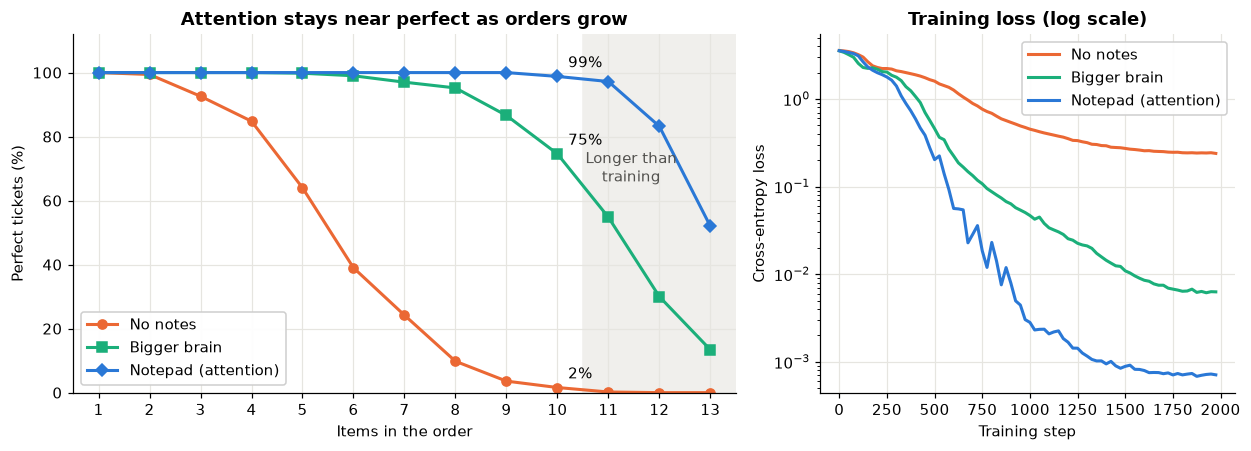

Waiter                 Parameters  Train time  5 items  10 items  13 items
No notes                  160,868         24s      64%        2%        0%
Bigger brain            1,801,316         24s     100%       75%       13%
Notepad (attention)       247,524         51s     100%       99%       52%


In [8]:
waiters = [("No notes", plain, PLAIN_COLOR, "o", plain_losses),
           ("Bigger brain", big, BIG_COLOR, "s", big_losses),
           ("Notepad (attention)", attn, ATTENTION_COLOR, "D", attn_losses)]
results = {name: score(model, test_bank) for name, model, *_ in waiters}
sizes = list(test_bank)

fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
left.axvspan(10.5, 13.5, color="#f0efec", zorder=0)
left.text(11.45, 66, "Longer than\ntraining", ha="center", color="#52514e")
for name, _, color, marker, _ in waiters:
    values = [results[name][n]["perfect"] for n in sizes]
    left.plot(sizes, values, color=color, marker=marker, markersize=6, linewidth=2, label=name)
    left.annotate(f"{values[9]:.0f}%", (10, values[9]), textcoords="offset points", xytext=(7, 6), ha="left")
left.set(title="Attention stays near perfect as orders grow", xlabel="Items in the order",
         ylabel="Perfect tickets (%)", xticks=sizes, ylim=(0, 112), xlim=(0.5, 13.5))
left.legend(loc="lower left", framealpha=0.95)

for name, _, color, _, losses in waiters:
    smooth = torch.tensor(losses).unfold(0, 25, 25).mean(1)
    right.plot(range(0, 25 * len(smooth), 25), smooth, color=color, linewidth=2, label=name)
right.set_yscale("log")
right.set(title="Training loss (log scale)", xlabel="Training step", ylabel="Cross-entropy loss")
right.legend(framealpha=0.95)
plt.tight_layout(); plt.show()

print(f"{'Waiter':<22}{'Parameters':>11}{'Train time':>12}{'5 items':>9}{'10 items':>10}{'13 items':>10}")
for name, model, *_ in waiters:
    r = results[name]
    print(f"{name:<22}{model.n_params:>11,}{model.train_seconds:>11.0f}s"
          f"{r[5]['perfect']:>8.0f}%{r[10]['perfect']:>9.0f}%{r[13]['perfect']:>9.0f}%")

### Reading the showdown

*Exact numbers shift by a few points each time you train.*

- **No notes** collapses, as in Notebook 1: only 1–2% perfect tickets at 10 items.
- **Bigger brain** is a real improvement, and it's important to be honest about that. More memory does help: roughly 70–75% at 10 items. But it took about **7× the parameters** of the notepad waiter, and it's still sliding. Bigger memory *delays* the bottleneck, without removing it.
- **Notepad** gets about 99% at 10 items with a far smaller model, and its loss ends up lower than the others.
- **Beyond training (grey area):** at 13 items the notepad still gets about half of the tickets right, against roughly 10% for the bigger brain. It's starting to slip too, so attention isn't magic. But a waiter who looks things up copes much better with longer orders than one who must memorize them.
- **The price:** the notepad took about twice as long to train, because each ticket word now means reading every note.

Now the same long order, handed to each waiter. The coke is said **last**, but it has to be written **first**.

In [9]:
LONG_SAID = tidy("hi can i get four cookies plus a burger , six salads and four donuts and nine cakes and two cokes thanks")
LONG_TICKET = "2 coke 1 burger 6 salad 4 cookie 4 donut 9 cake".split()
print("Customer:", " ".join(LONG_SAID), "\n")
for name, model, *_ in waiters:
    show_ticket(LONG_TICKET, read_tickets(model, [(LONG_SAID, [])])[0], name)
    print()

Customer: hi can i get four cookies plus a burger , six salads and four donuts and nine cakes and two cokes thanks 

No notes:
   ✓ 2 coke
   ✗ 6 burger
   ✗ 1 salad
   ✓ 4 cookie
   ✓ 4 donut
   ✓ 9 cake
   Should also have had: 1 burger, 6 salad

Bigger brain:
   ✓ 2 coke
   ✓ 1 burger
   ✓ 6 salad
   ✓ 4 cookie
   ✓ 4 donut
   ✓ 9 cake
   Perfect ticket!

Notepad (attention):
   ✓ 2 coke
   ✓ 1 burger
   ✓ 6 salad
   ✓ 4 cookie
   ✓ 4 donut
   ✓ 9 cake
   Perfect ticket!



## Experiment 3: read the waiter's eyes 👀

With attention we can see **which word the model looks at while writing each ticket word**. Each row is one written word, and a darker square means more attention on that spoken word.

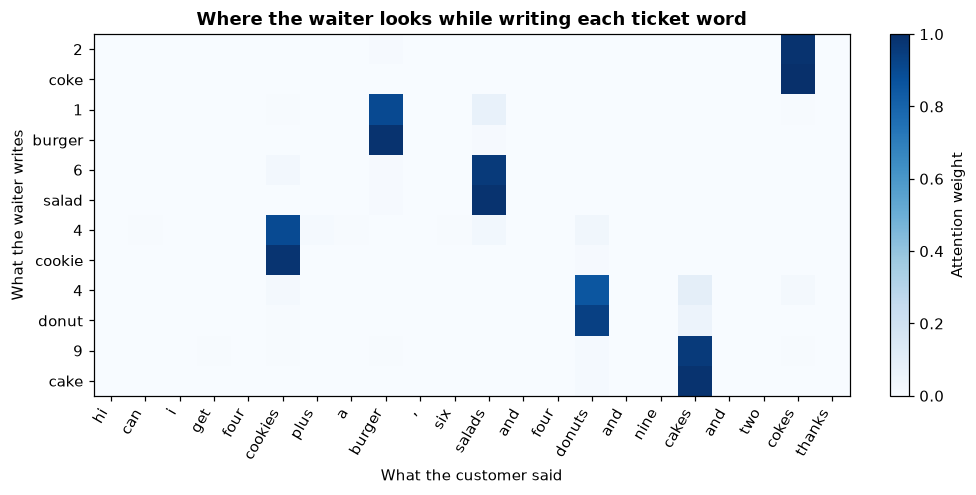

The same thing as a read-along, with the most-looked-at word in [brackets]:

2 coke      <- hi can i get four cookies plus a burger , six salads and four donuts and nine cakes and two [cokes] thanks
1 burger    <- hi can i get four cookies plus a [burger] , six salads and four donuts and nine cakes and two cokes thanks
6 salad     <- hi can i get four cookies plus a burger , six [salads] and four donuts and nine cakes and two cokes thanks
4 cookie    <- hi can i get four [cookies] plus a burger , six salads and four donuts and nine cakes and two cokes thanks
4 donut     <- hi can i get four cookies plus a burger , six salads and four [donuts] and nine cakes and two cokes thanks
9 cake      <- hi can i get four cookies plus a burger , six salads and four donuts and nine [cakes] and two cokes thanks


In [10]:
def look(said, smudged_words=()):
    """Returns the ticket and the attention weights for one order."""
    src, src_len, _ = make_batch([(said, [])])
    smudged = torch.tensor([[w in smudged_words for w in said]], device=device)
    ids, looked_at = attn.generate(src, src_len, smudged)
    ticket = ids_to_words(ids[0].tolist())
    weights = torch.stack(looked_at)[:, 0].cpu()[:len(ticket)]
    return ticket, weights

def draw_attention(ax, weights, said, ticket, title):
    image = ax.imshow(weights, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(said)), said, rotation=60, ha="right")
    ax.set_yticks(range(len(ticket)), ticket)
    ax.set_title(title); ax.grid(False)
    ax.spines[["top", "right"]].set_visible(True)
    return image

ticket, weights = look(LONG_SAID)
fig, ax = plt.subplots(figsize=(9, 4.6))
image = draw_attention(ax, weights, LONG_SAID, ticket, "Where the waiter looks while writing each ticket word")
ax.set_xlabel("What the customer said"); ax.set_ylabel("What the waiter writes")
fig.colorbar(image, ax=ax, label="Attention weight", fraction=0.025)
plt.tight_layout(); plt.show()

print("The same thing as a read-along, with the most-looked-at word in [brackets]:\n")
for i in range(0, len(ticket), 2):
    focus = weights[i + 1].argmax().item()
    line = " ".join(f"[{w}]" if j == focus else w for j, w in enumerate(LONG_SAID))
    print(f"{ticket[i]} {ticket[i + 1]:<9} <- {line}")

**How to read this picture:**


- **It's not a diagonal.** Eyes jump to the *end* for `coke`, go back for `burger`, and so on. That's the kitchen's drinks → mains → desserts rule, visible in the attention.
- **Fillers get no attention.** "hi can i get", "and", and "thanks" stay almost blank.
- **Here's a puzzle.** When writing the quantity `2`, the model looks at `cokes`, not at `two`. Why? The answer is below.

In [11]:
# Is that puzzle just this one order? Let's check across many correct tickets.
random.seed(SEED + 2)
orders = [make_order(random.randint(3, 10)) for _ in range(1000)]
src, src_len, _ = make_batch(orders)
ids, looked_at = attn.generate(src, src_len)
looked_at = torch.stack(looked_at, dim=1).argmax(dim=2).tolist()

counts = {"quantity -> dish word": 0, "quantity -> number word": 0, "dish -> dish word": 0}
total = 0
for row, (said, gold), peaks in zip(ids.tolist(), orders, looked_at):
    if ids_to_words(row) != gold: continue
    for k, (qty, dish) in enumerate(split_items(gold)):
        position = said.index(dish if dish in said else plural(dish))
        counts["quantity -> dish word"]   += peaks[2 * k] == position
        counts["quantity -> number word"] += peaks[2 * k] == position - 1
        counts["dish -> dish word"]       += peaks[2 * k + 1] == position
        total += 1
print(f"Looked at {total:,} ticket items:")
for label, count in counts.items():
    print(f"   {label:<26}{100 * count / total:5.1f}%")

Looked at 6,399 ticket items:
   quantity -> dish word     100.0%
   quantity -> number word     0.0%
   dish -> dish word         100.0%


**Solving the puzzle:** a note isn't a copy of one word. It's the GRU's state *after* reading that word, so it also carries what came just before. The note at `cokes` is really "*…two cokes*", and so one glance gives both the dish and its quantity.

There's probably a deeper reason too. This encoder only reads forward, so the note at `two` can't know what's coming next. It can't tell the decoder "a drink is here", which makes it little use for finding the next drink.

> **Takeaway: attention looks at encoder *states*, not raw words.** Exercise 1 lets you test this by making the encoder read in both directions.

## Experiment 4: watch them learn to read 🎓

These are snapshots of the same order at four moments during training. The ticket is fixed, so that only the attention changes.

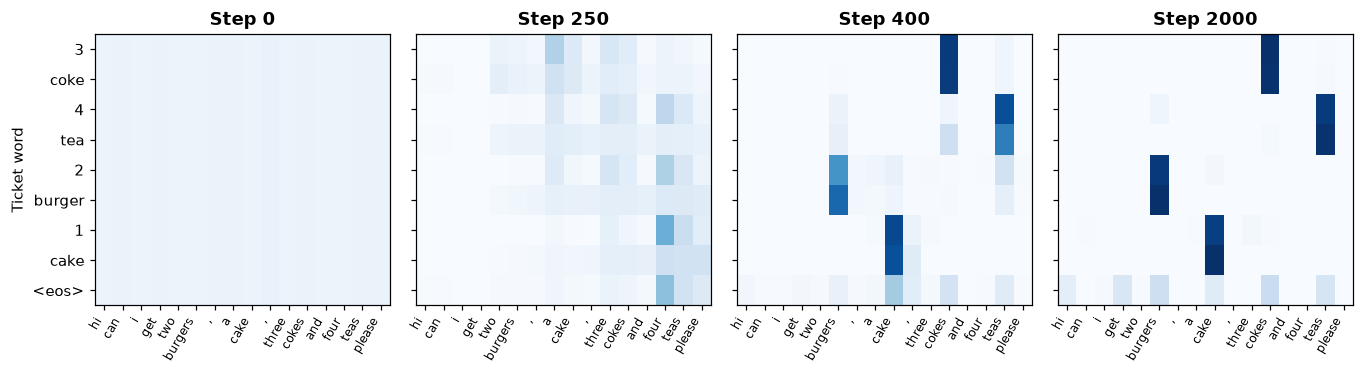

In [12]:
steps = sorted(snapshots)
fig, axes = plt.subplots(1, len(steps), figsize=(12.5, 3.5), sharey=True)
for ax, step in zip(axes, steps):
    draw_attention(ax, snapshots[step], PRACTICE_SAID, PRACTICE_TICKET + ["<eos>"], f"Step {step + 1 if step == 1999 else step}")
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("Ticket word")
plt.tight_layout(); plt.show()

- **Step 0:** the untrained model looks at everything about equally. Its "attention" is a nearly flat wash.
- **Steps 250–400:** focus appears while the loss is falling fastest.
- **Final step:** four sharp pairs of squares, one pair for each item.

**The bottom row is `<eos>`.** To finish, the waiter doesn't need any one word, so it never develops a single sharp focus there.

Nobody told the model which word goes with which ticket line. Our data has no alignment labels at all. It **discovered the alignment by itself**, because looking in the right place reduces the loss.

## Experiment 5: smudge the notepad 💧

Attention heat maps are beautiful, but a picture isn't proof. A model might look at a word without really using it (researchers debate this: see Jain & Wallace, 2019, *Attention is not Explanation*).

So let's run an **experiment instead of just observing**. We spill water on one note, so the decoder can't read it. Its memory stays intact, and only that note is hidden. If the notes matter, the ticket should change in a very specific way.

Clean notepad:   2 coke 1 burger 6 salad 4 cookie 4 donut 9 cake
Smudged 'salads': 2 coke 1 burger 4 cookie 4 donut 9 cake


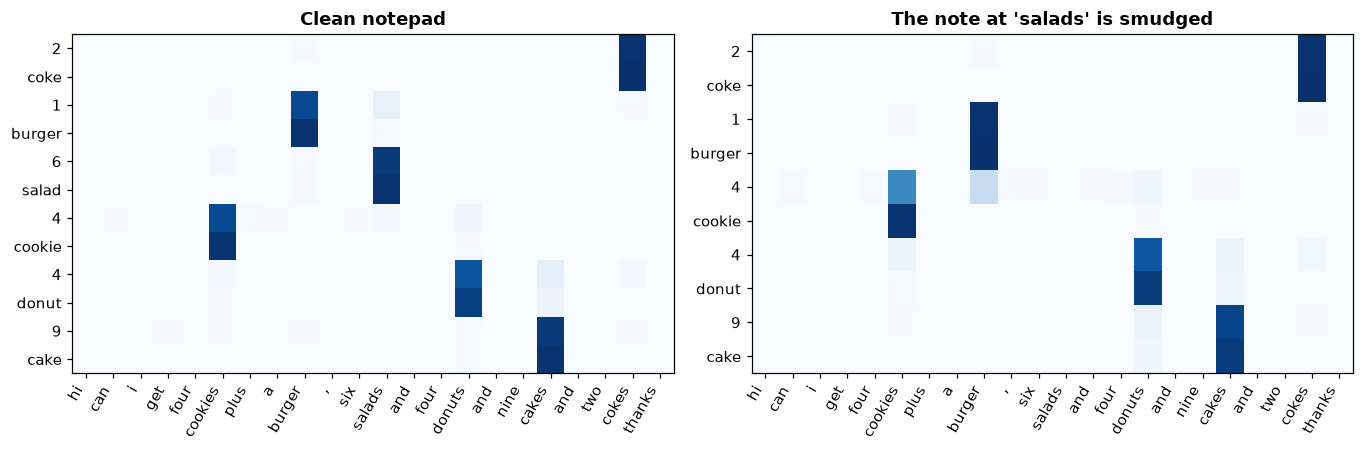

In [13]:
SMUDGE = ("salads",)
clean_ticket, clean_weights = look(LONG_SAID)
smudged_ticket, smudged_weights = look(LONG_SAID, SMUDGE)

print("Clean notepad:  ", " ".join(clean_ticket))
print("Smudged 'salads':", " ".join(smudged_ticket))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
draw_attention(axes[0], clean_weights, LONG_SAID, clean_ticket, "Clean notepad")
draw_attention(axes[1], smudged_weights, LONG_SAID, smudged_ticket, "The note at 'salads' is smudged")
plt.tight_layout(); plt.show()

One order could be luck. So here's the real test: **1,000 orders**, smudging one note in each, in three ways. The filler word acts as our **control**.

In [14]:
random.seed(SEED + 3)
orders = [make_order(random.randint(4, 8)) for _ in range(1000)]
src, src_len, _ = make_batch(orders)
targets = [random.choice(split_items(gold)) for _, gold in orders]

def smudge_test(where):
    """Smudges one word per order, then checks the target item and all the other items."""
    smudged = torch.zeros_like(src, dtype=torch.bool)
    for i, ((said, _), (_, dish)) in enumerate(zip(orders, targets)):
        position = said.index(dish if dish in said else plural(dish))
        smudged[i, {"filler": 0, "number": position - 1, "dish": position}[where]] = True
    ids, _ = attn.generate(src, src_len, smudged)
    target_kept = others_kept = others_total = 0
    for row, (_, gold), target in zip(ids.tolist(), orders, targets):
        pred = split_items(ids_to_words(row))
        target_kept += target in pred
        others = [item for item in split_items(gold) if item != target]
        others_kept += sum(item in pred for item in others)
        others_total += len(others)
    return 100 * target_kept / len(orders), 100 * others_kept / others_total

print(f"{'Smudged note':<32}{'Chosen item survives':>21}{'Other items survive':>21}")
for where, label in (("filler", "Opening filler word (control)"),
                     ("number", "Item's number word"),
                     ("dish", "Item's dish word")):
    kept, others = smudge_test(where)
    print(f"{label:<32}{kept:>20.1f}%{others:>20.1f}%")

Smudged note                     Chosen item survives  Other items survive
Opening filler word (control)                  100.0%               100.0%
Item's number word                             100.0%               100.0%
Item's dish word                                 0.2%                97.3%


### What the smudge test proves

- **Control (filler word):** almost nothing changes. Good: our test isn't breaking things on its own.
- **Number word:** almost nothing changes here either! That confirms our puzzle's answer. The model never relied on the note at `two`, because the note at `cokes` already carries the quantity.
- **Dish word:** the chosen item **almost never survives**, while nearly all the others do.

So hiding one note removes *that one item* from the ticket. Look at the single example above: the salads simply vanish, and the waiter moves smoothly on to the cookies.

Also notice what we *didn't* touch: the encoder's memory still went to the decoder. This waiter has learned to rely on the notepad.

> **A scientific habit worth keeping:** we made a prediction, used a control, and tested it on many examples. This shows attention is really used **in this model, on this task**. It doesn't prove that attention maps are trustworthy explanations in every model.

## Experiment 6: try to break it 🔨

Attention fixed the memory problem, not every problem. Run the cell below, then invent your own orders and try to confuse the waiter.

In [15]:
def take_order(text):
    said = tidy(text)
    ticket, weights = look(said)
    print("Customer:", " ".join(said))
    print("Ticket:  ", " ".join(ticket), "\n")

print("A brand-new dish: 'sushi'")
take_order("i would like two sushis and a coke")

print("The same dish twice (never happens in training)")
take_order("give me two cokes , a burger and three cokes")

print("Numbers that were never said: 'twelve'")
take_order("give me twelve burgers and a coke")

print("A different sentence style")
take_order("a coke")
take_order("burgers")

A brand-new dish: 'sushi'
Never heard these words, ignoring them: ['sushis']
Customer: i would like two and a coke
Ticket:   1 coke 

The same dish twice (never happens in training)
Customer: give me two cokes , a burger and three cokes
Ticket:   2 coke 3 coke 1 burger 

Numbers that were never said: 'twelve'
Never heard these words, ignoring them: ['twelve']
Customer: give me burgers and a coke
Ticket:   1 coke 

A different sentence style
Customer: a coke
Ticket:   1 coke 1 coke 1 soup 1 brownie 

Customer: burgers
Ticket:   burger burger burger burger burger burger burger burger burger burger 



### What broke, and why it matters

*These are the results from our run. Yours may differ, so read your own output too.*

| Test | What happened | The lesson |
|---|---|---|
| New dish (`sushis`) | The word is dropped, and the ticket silently omits it | A fixed vocabulary can't handle new words. Real systems use subword tokens or copy mechanisms |
| Same dish twice | It listed both lines, which is sensible | One example isn't proof: see Exercise 4 |
| Unknown number (`twelve`) | The burgers vanished too, with no warning from the model | Without its number, the item no longer looks like what it learned |
| Fragments (`a coke`, `burgers`) | It invented extra items, or repeated itself in a loop | The model doesn't know when it is out of its depth, and it never says "I don't know" |

Attention fixed the **memory bottleneck**. It didn't add judgment or the ability to handle things outside the training data.

## From the notepad to Transformers

You have now seen the core idea behind Transformers. Their famous terminology maps directly onto our waiter:

| Transformer term | In our waiter | Question it answers |
|---|---|---|
| **Query** | Decoder state, "what do I need?" | What am I looking for? |
| **Key** | The note, used for scoring | What does this note offer? |
| **Value** | The note, used for blending | What do I take away from it? |

In our model, one encoder state plays both Key and Value. Transformers learn separate versions, and use a dot product for the score. Their big step is to ask: *if the notes are so useful, do we still need a GRU's memory at all?* The answer is the title of the 2017 paper, **Attention Is All You Need**. See `13-Transformers`.

## What to remember

1. **The bottleneck was the real problem.** A bigger memory only delays failure and costs far more parameters.
2. **Attention = score, softmax, blend**, repeated for every word written.
3. **Notes are states, not words.** Each note carries context from the words before it.
4. **Attention can be tested.** Interfere with it and see what changes, as in the smudge test.
5. **There's a price.** Each ticket word now requires reading every note, so training took about twice as long per step here.

## Exercises

1. **Read both ways.** Use `bidirectional=True` in the encoder (you'll need to adapt the note and memory sizes). Does the quantity now look at the number word?
2. **A cheaper glance.** Replace the additive score with a dot product, as in Experiment 1. Is accuracy the same? And the speed?
3. **Train short, test long.** Train only on orders of 1–5 items. Which waiter handles 10-item orders better?
4. **Say it twice.** Our menu sampling never repeats a dish. Test many orders with repeats, like "two cokes and three cokes". Does the waiter cope? What *should* the ticket say?
5. **Change the kitchen's rule.** Sort by quantity, largest first. How does the attention map change?

**References:** Sutskever et al. (2014), *Sequence to Sequence Learning with Neural Networks* · Bahdanau et al. (2015), *Neural Machine Translation by Jointly Learning to Align and Translate* · Jain & Wallace (2019), *Attention is not Explanation* · Vaswani et al. (2017), *Attention Is All You Need*